# Interference - Rectangular Aperture

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch04/ch04-03.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** run the setup cell below first. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

In [ ]:
# --- Setup: run this cell first.  It does nothing outside Google Colab. ---
import sys, os, importlib.util, urllib.request
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # interactive matplotlib (%matplotlib widget) needs ipympl and Colab's custom widget manager
    if importlib.util.find_spec("ipympl") is None:
        get_ipython().run_line_magic("pip", "install -q ipympl")
        importlib.invalidate_caches()  # make the freshly installed package importable
        try:  # matplotlib caches its backend list on first use; refresh it so no restart is needed
            from matplotlib.backends.registry import backend_registry
            backend_registry._clear()
        except Exception:
            pass
    import ipympl  # noqa: F401
    from google.colab import output
    output.enable_custom_widget_manager()
    print("Colab setup done. If a %matplotlib widget cell still errors, use Runtime > Restart session, then Run all.")

## Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, PowerNorm
from matplotlib import cm
from matplotlib.colors import LightSource

In [2]:
%matplotlib inline
# Define global "bold" style parameters
# This restores the thicker lines and fonts seen in older versions
plot_params = {
    # --- Fonts ---
    'font.size': 18,
    'font.family': 'sans-serif',
    
    # --- Axes (The Box) ---
    'axes.linewidth': 1.0,       # Thicker box around the plot
    
    # --- Lines (The Signal) ---
    'lines.linewidth': 2.5,      # Thicker default plot lines
}

# Apply these settings globally
plt.rcParams.update(plot_params)

## Define parameters

In [3]:
# --- Parameters ---
L1 = 2 * 10**6       # Distance to screen in microns
wavelength1 = 0.632  # Wavelength in microns
ax1 = 40             # slit width in x in microns
ay1 = 40             # slit width in y in microns

# --- Data Generation ---
# Generate x values from -10^5 to 10^5
numpointsx1 = 512
numpointsy1 = numpointsx1
x1 = np.linspace(-1e5,1e5,num=numpointsx1)
y1 = x1

# Create a 2D grid of (x,y) points
X1, Y1 = np.meshgrid(x1, y1)
intensity1_2d = (np.sin(np.pi*ax1/wavelength1*X1/np.sqrt(X1**2+Y1**2+L1**2))/(np.pi*ax1/wavelength1*X1/np.sqrt(X1**2+Y1**2+L1**2)))**2 *(np.sin(np.pi*ay1/wavelength1*Y1/np.sqrt(X1**2+Y1**2+L1**2))/(np.pi*ay1/wavelength1*Y1/np.sqrt(X1**2+Y1**2+L1**2)))**2
# Fix NaN at center if x hits 0 exactly
intensity1_2d = np.nan_to_num(intensity1_2d, nan=1.0)

## Plot

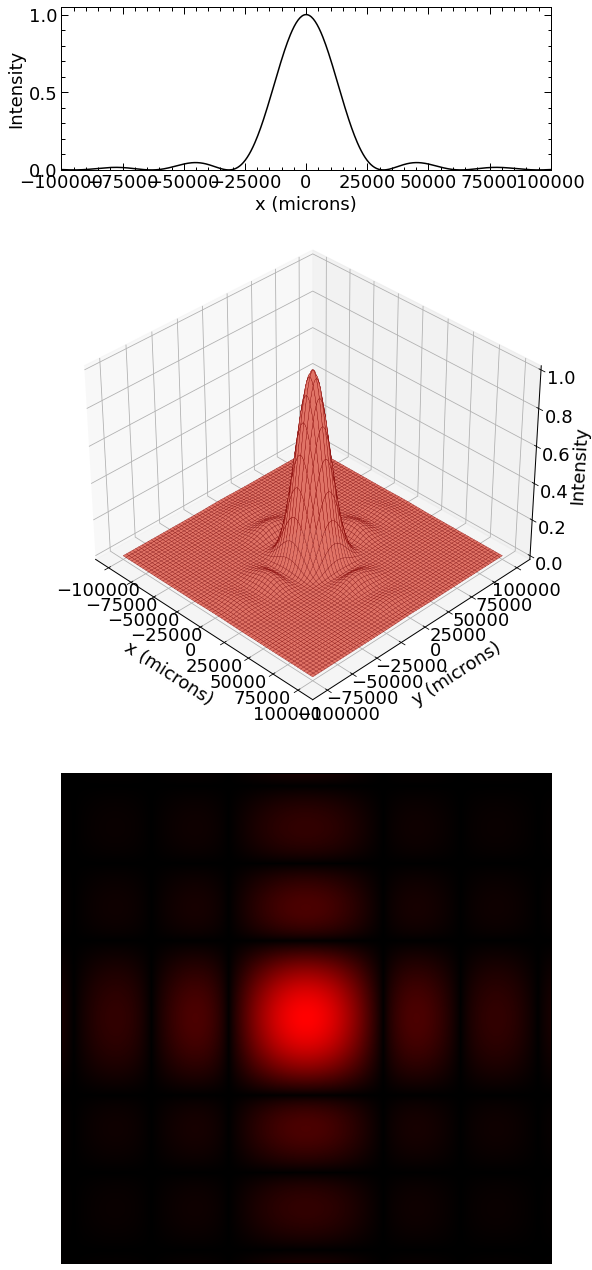

In [4]:

# --- Plotting ---
textsize1 = 18
#Sets the default font style and size in plots
font = {'family' : 'sans-serif',
        'size'   : textsize1}

plt.rc('font', **font)

fig1, (ax11, ax12, ax13) = plt.subplots(3, 1, figsize=(10, 18), 
                                        gridspec_kw={'height_ratios': [1, 3, 3]})

# line plot
# ax11 = fig1.add_subplot(3,1,1)
mid_index = numpointsx1 // 2 # slice the middle row of the 2D array
intensity1 = intensity1_2d[mid_index, :] # slice where y is approx 0

ax11.plot(x1, intensity1, color='k', linewidth=1.5)
ax11.set_xlim(-10**5, 10**5)
ax11.set_ylim(0, 1.05)
ax11.set_xlabel("x (microns)")
ax11.set_ylabel("Intensity")
ax11.minorticks_on()
ax11.tick_params(which='both',direction="in",width=1)
ax11.tick_params(which='major',length=7)
ax11.tick_params(which='minor',length=3.5)
ax11.xaxis.set_ticks_position('both')
ax11.yaxis.set_ticks_position('both')

# 3D plot
ax12.remove()
ax12 = fig1.add_subplot(3, 1, 2, projection='3d')

ls = LightSource(azdeg=315, altdeg=45) # This simulates a sun/lamp at a specific azimuth/elevation to create shadows

surf12 = ax12.plot_surface(X1, Y1, intensity1_2d, 
                       rstride=8, cstride=8,        # Control grid density (lower = more grid lines)
                       color='salmon',              # Base material color
                       edgecolor='maroon',          # Grid line color
                       linewidth=0.3,               # Grid line width
                       shade=True,
                       lightsource=ls,
                       antialiased=True)

# ax12.set_title(f"Rectangular Aperture")
ax12.set_xlabel("x (microns)", labelpad=15)
ax12.set_ylabel("y (microns)", labelpad=15)
ax12.set_zlabel("Intensity")
ax12.set_zlim(0, 1)

# Set standard white background (cleaner look)
ax12.set_facecolor('white') 
fig1.patch.set_facecolor('white')

# Set view angle
ax12.view_init(elev=35, azim=-45)

# density plot
# ax13 = fig1.add_subplot(3, 1, 3)
colors = [(0, 0, 0), (1, 0, 0)] # Black to Red
laser_cmap = LinearSegmentedColormap.from_list("laser_red", colors)

ax13.imshow(intensity1_2d, aspect='equal', cmap=laser_cmap,
           norm=PowerNorm(gamma=0.4))

ax13.set_xticks([]) # Remove x ticks for the density plot
ax13.set_yticks([]) # Remove y ticks as they are arbitrary
ax13.tick_params(direction='in')

plt.tight_layout()
plt.subplots_adjust(hspace=0.15) # Reduce space between plots

# Force a draw so we can read the final position of the square plot
fig1.canvas.draw() 

# Get positions
box12 = ax12.get_position() # The square plot
box11 = ax11.get_position() # The wide line plot

# Apply the width/left-position of the square plot to the line plot
ax11.set_position([box12.x0, box11.y0, box12.width, box11.height])
plt.show()


## Animation

In [ ]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, PowerNorm, LightSource
from matplotlib import cm
import ipywidgets as widgets
from IPython.display import display

# --- 1. Global Setup ---
plot_params = {
    'font.size': 10,
    'font.family': 'sans-serif',
    'axes.linewidth': 1.0,
    'lines.linewidth': 2.0,
}
plt.rcParams.update(plot_params)

# Constants
L1 = 2 * 10**6      
X_RANGE = 1e5       
NUM_POINTS = 512    

# Data Generation
x1 = np.linspace(-X_RANGE, X_RANGE, num=NUM_POINTS)
y1 = x1
X1, Y1 = np.meshgrid(x1, y1)

# Pre-calc Distance
R_dist = np.sqrt(X1**2 + Y1**2 + L1**2)

# --- 2. Helper: Wavelength to RGB ---
def wavelength_to_rgb(wavelength):
    wl = float(wavelength)
    if 380 <= wl <= 440: R,G,B = -(wl - 440)/(60), 0.0, 1.0
    elif 440 < wl <= 490: R,G,B = 0.0, (wl - 440)/(50), 1.0
    elif 490 < wl <= 510: R,G,B = 0.0, 1.0, -(wl - 510)/(20)
    elif 510 < wl <= 580: R,G,B = (wl - 510)/(70), 1.0, 0.0
    elif 580 < wl <= 645: R,G,B = 1.0, -(wl - 645)/(65), 0.0
    elif 645 < wl <= 750: R,G,B = 1.0, 0.0, 0.0
    else: R,G,B = 0.0, 0.0, 0.0
    return (R, G, B)

# --- 3. Figure Initialization ---
fig = plt.figure(figsize=(12, 4))
fig.canvas.header_visible = False
fig.canvas.footer_visible = False

ax1 = fig.add_subplot(1, 3, 1)
ax2 = fig.add_subplot(1, 3, 2, projection='3d')
ax3 = fig.add_subplot(1, 3, 3)

# Initial Calculation
def calc_intensity(ax_val, ay_val, w_val):
    term_x = (np.pi * ax_val * X1) / (w_val * R_dist)
    term_y = (np.pi * ay_val * Y1) / (w_val * R_dist)
    with np.errstate(divide='ignore', invalid='ignore'):
        Ix = (np.sin(term_x) / term_x)**2
        Iy = (np.sin(term_y) / term_y)**2
    return np.nan_to_num(Ix*Iy, nan=1.0)

I_init = calc_intensity(40.0, 40.0, 0.632)
rgb_init = wavelength_to_rgb(632)

# --- Plot Artists ---

# 1. Line Plot (Cross Section)
mid_idx = NUM_POINTS // 2
line_plot, = ax1.plot(x1, I_init[mid_idx, :], color=rgb_init)
ax1.set_ylim(0, 1.05)
ax1.set_xlim(-X_RANGE, X_RANGE)
ax1.set_title("Cross Section (y=0)")
ax1.minorticks_on()

# 2. 3D Plot (ENHANCED)
# A. Increase resolution (downsample less)
down = 4  # 512/4 = 128 points grid (smoother than 8)
X_3d = X1[::down, ::down]
Y_3d = Y1[::down, ::down]
surf_plot = [None] 

def draw_3d_surface(Z_data, color_rgb):
    if surf_plot[0]: surf_plot[0].remove()
    
    Z_sub = Z_data[::down, ::down]
    
    # B. VISUAL TRICK: Apply Power (Gamma) to the Z-Geometry
    # This physically lifts the small side lobes so you can see them in 3D
    Z_visual = np.power(Z_sub, 0.3) 
    
    # Create a colormap matching the laser color
    # Darker version for low points, bright version for peaks
    custom_cmap = LinearSegmentedColormap.from_list("laser_3d", [(0,0,0), color_rgb, (1,1,1)])
    
    surf_plot[0] = ax2.plot_surface(
        X_3d, Y_3d, Z_visual, # Plotting the "lifted" data
        rstride=1, cstride=1,
        cmap=custom_cmap,     # Color mapped to height
        linewidth=0,          # Remove grid lines for smoothness
        antialiased=False,
        shade=False           # Let cmap handle the depth perception
    )

draw_3d_surface(I_init, rgb_init)
ax2.set_zlim(0, 1)
ax2.set_title("3D Profile (Log-Scaled Height)")
ax2.set_xticks([]); ax2.set_yticks([]); ax2.set_zticks([])
ax2.view_init(elev=45, azim=-45)

# 3. Density Plot
cmap_laser = LinearSegmentedColormap.from_list("laser", [(0,0,0), rgb_init])
img_plot = ax3.imshow(I_init, extent=[-X_RANGE, X_RANGE, -X_RANGE, X_RANGE],
                      cmap=cmap_laser, norm=PowerNorm(gamma=0.4, vmin=0, vmax=1),
                      aspect='equal')
ax3.set_xticks([]); ax3.set_yticks([])
ax3.set_title("Diffraction Pattern")

plt.tight_layout()

# --- 4. Controls ---
def update_simulation(ax_val, ay_val, w_val):
    new_I = calc_intensity(ax_val, ay_val, w_val)
    new_color = wavelength_to_rgb(w_val * 1000)
    
    # Update Line
    line_plot.set_ydata(new_I[mid_idx, :])
    line_plot.set_color(new_color)
    
    # Update Image
    img_plot.set_data(new_I)
    new_cmap = LinearSegmentedColormap.from_list("laser", [(0,0,0), new_color])
    img_plot.set_cmap(new_cmap)
    
    # Update 3D
    draw_3d_surface(new_I, new_color)
    
    fig.canvas.draw_idle()

def on_change(change):
    update_simulation(s_ax.value, s_ay.value, s_w.value)

s_ax = widgets.FloatSlider(value=40, min=10, max=100, step=2, description='Ax (um)')
s_ay = widgets.FloatSlider(value=40, min=10, max=100, step=2, description='Ay (um)')
s_w  = widgets.FloatSlider(value=0.632, min=0.400, max=0.700, step=0.001, description='Lambda')

s_ax.observe(on_change, names='value')
s_ay.observe(on_change, names='value')
s_w.observe(on_change, names='value')

display(widgets.HBox([s_ax, s_ay, s_w]))

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch04/ch04-03_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch04/ch04-03.html) (direct link: [ch04-03_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch04/ch04-03_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.